<a href="https://colab.research.google.com/github/vyakhyaagoyal/DL_Lab_V/blob/main/LAB_8_Transfer_Learning_and_Fine_Tuning_(1).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Lab 7: Transfer Learning and Fine-Tuning of a Pre-Trained CNN

**Aim:** To use an ImageNet pre-trained model such as ResNet, VGG, GoogLeNet, EfficientNet, or a Vision Transformer for an image-classification task; compare feature extraction with selective fine-tuning; and analyse training time, validation performance, overfitting, and test performance.

**Mapped Course Outcome(s):** CO1, CO3, CO6

---

## What you will learn

In this lab you will:
- understand transfer learning using an ImageNet-pretrained model;
- perform image classification using **feature extraction**;
- perform **selective fine-tuning**;
- compare training/validation performance and training time;
- identify possible overfitting from learning curves; and
- evaluate the final model on a held-out test set.

> **Recommended environment:** Google Colab with GPU enabled.


## 1 - Import Libraries

We will use PyTorch and Torchvision. The notebook uses **CIFAR-10** so that the experiment is reproducible without manually preparing a large image dataset. The same workflow can later be applied to a custom folder-based dataset.


In [1]:
# If required in a fresh Colab runtime, uncomment:
# !pip -q install torch torchvision scikit-learn matplotlib pandas

import os
import time
import copy
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms, models

from sklearn.metrics import accuracy_score, classification_report, confusion_matrix


## 2 - Reproducibility and Device

A fixed random seed helps make results reproducible. The device variable selects CUDA/GPU when available; otherwise CPU is used.
Student Task
1. Run the block and record the device.
2. Explain why a GPU is useful for CNN training.
3. Change the seed and observe whether the exact results change.


In [2]:
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)


Using device: cpu


## Exercise 1 - Inspect the Dataset

CIFAR-10 contains 10 object classes. To keep the laboratory experiment manageable, we use a **four-class subset** by default.

**Task:** Change `SELECTED_CLASSES` to experiment with a different set of classes.
CIFAR-10 contains ten classes. We select four classes so the laboratory experiment remains computationally manageable. The labels are remapped to 0, 1, 2 and 3.
Student Task
1. Replace the four classes with another combination.
2. Record the new class mapping.
3. Explain why label remapping is required.



In [3]:
# You may change these four classes for experimentation.
SELECTED_CLASSES = ["airplane", "automobile", "cat", "dog"]

CLASS_TO_NEW = {name: i for i, name in enumerate(SELECTED_CLASSES)}

print("Selected classes:", SELECTED_CLASSES)
print("Class mapping:", CLASS_TO_NEW)


Selected classes: ['airplane', 'automobile', 'cat', 'dog']
Class mapping: {'airplane': 0, 'automobile': 1, 'cat': 2, 'dog': 3}


## 3 - Data Pre-processing

ImageNet-pretrained networks expect three-channel images and commonly use 224×224 input with ImageNet normalization.

Training data uses augmentation, while validation and test data use deterministic preprocessing.

Student Task
1. Change rotation from 10° to 20°.
2. Remove RandomHorizontalFlip() and compare the result.
3. Explain why augmentation is normally applied to training data rather than test data.

In [4]:
DATA_DIR = "./datasets"

IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD  = [0.229, 0.224, 0.225]

train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)
])

eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)
])


## 4 - Download and Prepare CIFAR-10

The dataset is downloaded automatically into the `datasets` folder.

We create train/validation/test subsets and remap the selected classes to labels 0, 1, 2, ...


In [6]:
# Download CIFAR-10
raw_train = datasets.CIFAR10(DATA_DIR, train=True, download=True)
raw_test  = datasets.CIFAR10(DATA_DIR, train=False, download=True)

# CIFAR-10 class names
CIFAR_CLASSES = raw_train.classes
print("Available classes:", CIFAR_CLASSES)

# Select indices belonging to chosen classes
selected_ids = [CIFAR_CLASSES.index(c) for c in SELECTED_CLASSES]

train_indices_all = [i for i, y in enumerate(raw_train.targets) if y in selected_ids]
test_indices_all  = [i for i, y in enumerate(raw_test.targets) if y in selected_ids]

# Reproducible shuffle
rng = np.random.default_rng(SEED)
rng.shuffle(train_indices_all)
rng.shuffle(test_indices_all)

# Keep the experiment compact enough for a lab
MAX_TRAIN_PER_CLASS = 1000
MAX_VAL_PER_CLASS = 250
MAX_TEST_PER_CLASS = 250

def balanced_indices(dataset, class_names, max_per_class, seed=42):
    class_ids = [dataset.class_to_idx[c] for c in class_names]
    rng = np.random.default_rng(seed)
    output = []
    for cid in class_ids:
        ids = [i for i, y in enumerate(dataset.targets) if y == cid]
        rng.shuffle(ids)
        output.extend(ids[:max_per_class])
    rng.shuffle(output)
    return output

train_core = balanced_indices(raw_train, SELECTED_CLASSES,
                              MAX_TRAIN_PER_CLASS + MAX_VAL_PER_CLASS, SEED)

train_idx = []
val_idx = []
for c in SELECTED_CLASSES:
    cid = raw_train.class_to_idx[c]
    ids = [i for i in train_core if raw_train.targets[i] == cid]
    train_idx.extend(ids[:MAX_TRAIN_PER_CLASS])
    val_idx.extend(ids[MAX_TRAIN_PER_CLASS:MAX_TRAIN_PER_CLASS+MAX_VAL_PER_CLASS])

test_idx = balanced_indices(raw_test, SELECTED_CLASSES, MAX_TEST_PER_CLASS, SEED)

# Separate dataset objects so train augmentation is not applied to validation/test.
train_full = datasets.CIFAR10(DATA_DIR, train=True, transform=train_transform, download=False)
val_full   = datasets.CIFAR10(DATA_DIR, train=True, transform=eval_transform, download=False)
test_full  = datasets.CIFAR10(DATA_DIR, train=False, transform=eval_transform, download=False)

train_set = Subset(train_full, train_idx)
val_set   = Subset(val_full, val_idx)
test_set  = Subset(test_full, test_idx)

print("Train images:", len(train_set))
print("Validation images:", len(val_set))
print("Test images:", len(test_set))


 84%|████████▍ | 143M/170M [39:21<07:37, 60.5kB/s]


KeyboardInterrupt: 

## 5 - Create Data Loaders
A DataLoader divides the dataset into mini-batches. Training data is shuffled so that the model does not see examples in exactly the same order in every epoch.
Student Task
1. Try batch sizes 16 or 64.
2. Record the number of batches.
3. Compare memory use/training speed if a GPU is available.
4. Explain the effect of batch size on training.


In [ ]:
BATCH_SIZE = 32

train_loader = DataLoader(train_set, batch_size=BATCH_SIZE, shuffle=True,
                          num_workers=2, pin_memory=torch.cuda.is_available())
val_loader = DataLoader(val_set, batch_size=BATCH_SIZE, shuffle=False,
                        num_workers=2, pin_memory=torch.cuda.is_available())
test_loader = DataLoader(test_set, batch_size=BATCH_SIZE, shuffle=False,
                         num_workers=2, pin_memory=torch.cuda.is_available())

print("Number of training batches:", len(train_loader))
print("Number of validation batches:", len(val_loader))
print("Number of test batches:", len(test_loader))


Number of training batches: 125
Number of validation batches: 32
Number of test batches: 32


## Exercise 2 - Visualize Sample Images

Display a batch of images after reversing ImageNet normalization.

**Task:** Observe whether augmentation changes the appearance of the images.


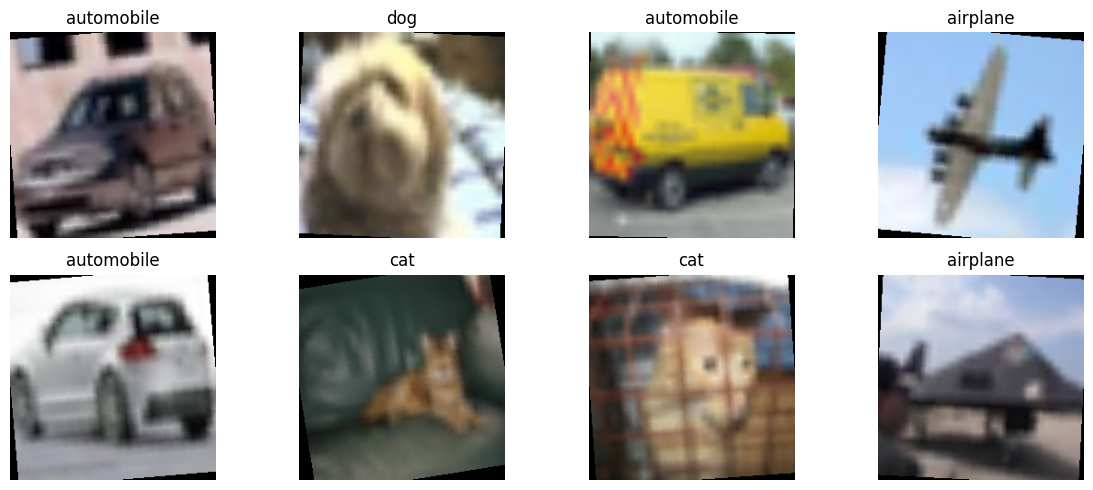

In [ ]:
def show_batch(loader, class_names, n=8):
    images, labels = next(iter(loader))
    images = images[:n].cpu()
    labels = labels[:n].cpu()

    mean = torch.tensor(IMAGENET_MEAN).view(3,1,1)
    std = torch.tensor(IMAGENET_STD).view(3,1,1)
    images = (images * std + mean).clamp(0, 1)

    plt.figure(figsize=(12, 5))
    for i in range(len(images)):
        ax = plt.subplot(2, 4, i+1)
        plt.imshow(images[i].permute(1,2,0))
        # Map the original CIFAR-10 label to the new sequential index
        # using the global CLASS_TO_NEW and CIFAR_CLASSES dictionaries.

        mapped_label_idx = CLASS_TO_NEW[CIFAR_CLASSES[labels[i].item()]]
        plt.title(class_names[mapped_label_idx])
        plt.axis("off")
    plt.tight_layout()
    plt.show()

show_batch(train_loader, SELECTED_CLASSES)

## 6 - Load an ImageNet Pre-trained ResNet18

For the main experiment we use **ResNet18**.
ResNet18 is loaded with ImageNet weights. The model has already learned useful visual features such as edges, textures, shapes and object patterns.
This is the central idea of transfer learning: reuse knowledge learned from a large source dataset for a new target task.

The same experiment can be repeated with VGG, GoogLeNet, or EfficientNet by changing the model-loading section.


In [ ]:
# Load ImageNet-pretrained ResNet18
weights = models.ResNet18_Weights.DEFAULT
model_fe = models.resnet18(weights=weights)

print("Original classifier:", model_fe.fc)


Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 125MB/s]


Original classifier: Linear(in_features=512, out_features=1000, bias=True)


## Exercise 3 - Feature Extraction

In feature extraction, the pretrained backbone is frozen and only the new classification head is trained.

**Task:** Complete the two marked sections:
1. freeze the pretrained parameters;
2. replace the final fully connected layer with a layer for `len(SELECTED_CLASSES)` classes.


In [ ]:
def build_feature_extractor(num_classes):
    model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)

    # YOUR CODE STARTS HERE
    # Freeze all pretrained parameters
    for param in model.parameters():
        param.requires_grad = False
    # YOUR CODE ENDS HERE

    for param in model.parameters():
        param.requires_grad = False

    # Replace the final classifier
    model.fc = nn.Linear(model.fc.in_features, num_classes)

    # YOUR CODE ENDS HERE

    return model

model_fe = build_feature_extractor(len(SELECTED_CLASSES))

### Check Exercise 3

The check below verifies that the classifier has the correct number of outputs and that the backbone is frozen.


In [ ]:
# Public-style checks
assert model_fe.fc.out_features == len(SELECTED_CLASSES), "Classifier output size is incorrect."
backbone_trainable = sum(p.requires_grad for n,p in model_fe.named_parameters()
                         if not n.startswith("fc."))
assert backbone_trainable == 0, "Pretrained backbone should be frozen."

print("All feature-extraction checks passed!")


All feature-extraction checks passed!


## 7 - Training and Validation Utilities

The function below records loss, accuracy, and training time so that feature extraction and fine-tuning can be compared fairly.


In [ ]:
def run_epoch(model, loader, criterion, optimizer=None):
    is_train = optimizer is not None
    model.train() if is_train else model.eval()

    running_loss = 0.0
    correct = 0
    total = 0

    context = torch.enable_grad() if is_train else torch.no_grad()

    with context:
        for images, labels in loader:
            images = images.to(device)
            labels = torch.tensor([
                CLASS_TO_NEW[raw_train.classes[y]]
                for y in labels.tolist()
            ], device=device)

            if is_train:
                optimizer.zero_grad()

            outputs = model(images)
            loss = criterion(outputs, labels)

            if is_train:
                loss.backward()
                optimizer.step()

            running_loss += loss.item() * images.size(0)
            correct += (outputs.argmax(1) == labels).sum().item()
            total += images.size(0)

    return running_loss / total, correct / total


def fit(model, train_loader, val_loader, criterion, optimizer, epochs=5):
    history = {"train_loss": [], "train_acc": [],
               "val_loss": [], "val_acc": []}

    start = time.time()

    for epoch in range(epochs):
        tr_loss, tr_acc = run_epoch(model, train_loader, criterion, optimizer)
        va_loss, va_acc = run_epoch(model, val_loader, criterion)

        history["train_loss"].append(tr_loss)
        history["train_acc"].append(tr_acc)
        history["val_loss"].append(va_loss)
        history["val_acc"].append(va_acc)

        print(
            f"Epoch {epoch+1:02d}/{epochs} | "
            f"Train Loss {tr_loss:.4f} | Train Acc {tr_acc:.4f} | "
            f"Val Loss {va_loss:.4f} | Val Acc {va_acc:.4f}"
        )

    elapsed = time.time() - start
    return history, elapsed


## 8 - Train the Feature-Extraction Model


In [ ]:
EPOCHS = 5

model_fe = model_fe.to(device)
criterion = nn.CrossEntropyLoss()

optimizer_fe = optim.Adam(
    filter(lambda p: p.requires_grad, model_fe.parameters()),
    lr=1e-3
)

history_fe, time_fe = fit(
    model_fe, train_loader, val_loader,
    criterion, optimizer_fe, epochs=EPOCHS
)

print(f"Feature-extraction training time: {time_fe:.2f} seconds")


Epoch 01/5 | Train Loss 0.7736 | Train Acc 0.7015 | Val Loss 0.4765 | Val Acc 0.8370
Epoch 02/5 | Train Loss 0.4754 | Train Acc 0.8277 | Val Loss 0.4392 | Val Acc 0.8290
Epoch 03/5 | Train Loss 0.4149 | Train Acc 0.8448 | Val Loss 0.3771 | Val Acc 0.8550
Epoch 04/5 | Train Loss 0.3909 | Train Acc 0.8502 | Val Loss 0.3423 | Val Acc 0.8690
Epoch 05/5 | Train Loss 0.3855 | Train Acc 0.8482 | Val Loss 0.3138 | Val Acc 0.8820
Feature-extraction training time: 2649.90 seconds


## 9 - Plot Learning Curves

A large gap between training and validation accuracy, or a validation loss that starts increasing while training loss continues to decrease, may indicate overfitting.


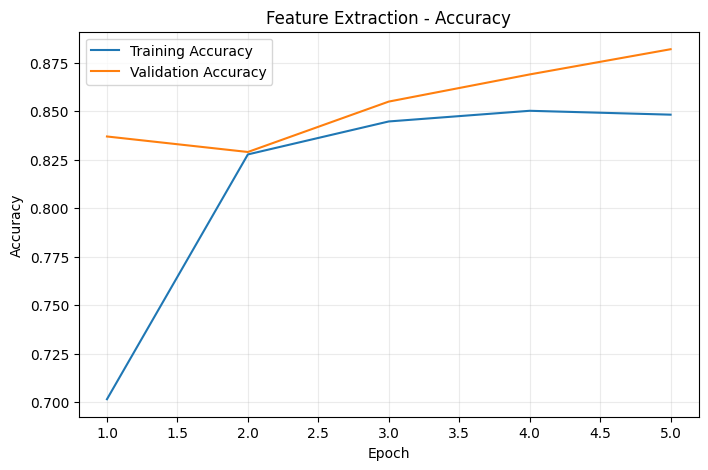

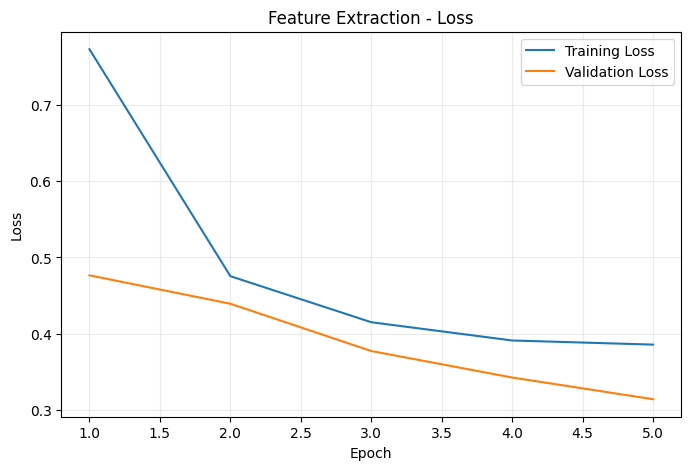

In [ ]:
def plot_history(history, title_prefix):
    epochs = range(1, len(history["train_acc"]) + 1)

    plt.figure(figsize=(8, 5))
    plt.plot(epochs, history["train_acc"], label="Training Accuracy")
    plt.plot(epochs, history["val_acc"], label="Validation Accuracy")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.title(title_prefix + " - Accuracy")
    plt.legend()
    plt.grid(alpha=0.25)
    plt.show()

    plt.figure(figsize=(8, 5))
    plt.plot(epochs, history["train_loss"], label="Training Loss")
    plt.plot(epochs, history["val_loss"], label="Validation Loss")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.title(title_prefix + " - Loss")
    plt.legend()
    plt.grid(alpha=0.25)
    plt.show()

plot_history(history_fe, "Feature Extraction")


## Exercise 4 - Selective Fine-Tuning

Now unfreeze only the **last residual block (`layer4`)** and the new classification head.

**Why?** Early CNN layers tend to capture more generic visual patterns, while deeper layers are more task-specific.

**Task:** Complete the marked line(s) so that `layer4` becomes trainable while earlier layers remain frozen.


In [ ]:
def build_fine_tuned_model(num_classes):
    model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)

    # Freeze the complete pretrained network first
    for param in model.parameters():
        param.requires_grad = False

    # YOUR CODE STARTS HERE
    # Unfreeze only the final residual block
    for param in model.layer4.parameters():
        param.requires_grad = True
    # YOUR CODE ENDS HERE

    model.fc = nn.Linear(model.fc.in_features, num_classes)
    return model

model_ft = build_fine_tuned_model(len(SELECTED_CLASSES))

# Checks
layer4_trainable = sum(p.requires_grad for p in model_ft.layer4.parameters())
layer1_trainable = sum(p.requires_grad for p in model_ft.layer1.parameters())

assert layer4_trainable > 0, "layer4 should be trainable."
assert layer1_trainable == 0, "Earlier layers should remain frozen."

print("All fine-tuning checks passed!")

All fine-tuning checks passed!


## 10 - Train the Fine-Tuned Model

Use a **smaller learning rate** than feature extraction because pretrained weights should be changed gradually.


In [ ]:
model_ft = model_ft.to(device)

optimizer_ft = optim.Adam(
    filter(lambda p: p.requires_grad, model_ft.parameters()),
    lr=1e-4
)

history_ft, time_ft = fit(
    model_ft, train_loader, val_loader,
    criterion, optimizer_ft, epochs=EPOCHS
)

print(f"Fine-tuning training time: {time_ft:.2f} seconds")


Epoch 01/5 | Train Loss 0.3864 | Train Acc 0.8415 | Val Loss 0.2260 | Val Acc 0.9180
Epoch 02/5 | Train Loss 0.1983 | Train Acc 0.9235 | Val Loss 0.1858 | Val Acc 0.9290
Epoch 03/5 | Train Loss 0.1546 | Train Acc 0.9377 | Val Loss 0.1738 | Val Acc 0.9330
Epoch 04/5 | Train Loss 0.1088 | Train Acc 0.9600 | Val Loss 0.1927 | Val Acc 0.9190
Epoch 05/5 | Train Loss 0.0840 | Train Acc 0.9692 | Val Loss 0.2044 | Val Acc 0.9240
Fine-tuning training time: 3363.22 seconds


## 11 - Plot Fine-Tuning Curves


In [ ]:
plot_history(history_ft, "Selective Fine-Tuning")


## 12 - Evaluate on the Test Set


In [ ]:
def evaluate(model, loader):
    model.eval()
    y_true, y_pred = [], []

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)

            mapped_labels = [
                CLASS_TO_NEW[raw_test.classes[y]]
                for y in labels.tolist()
            ]

            outputs = model(images)
            preds = outputs.argmax(1).cpu().tolist()

            y_true.extend(mapped_labels)
            y_pred.extend(preds)

    acc = accuracy_score(y_true, y_pred)
    return acc, y_true, y_pred

acc_fe, y_true_fe, y_pred_fe = evaluate(model_fe, test_loader)
acc_ft, y_true_ft, y_pred_ft = evaluate(model_ft, test_loader)

print(f"Feature Extraction Test Accuracy: {acc_fe:.4f}")
print(f"Fine-Tuning Test Accuracy:        {acc_ft:.4f}")


## 13 - Classification Report and Confusion Matrix

Analyse class-wise precision, recall and F1-score.


In [ ]:
print("=== Feature Extraction ===")
print(classification_report(y_true_fe, y_pred_fe,
                            target_names=SELECTED_CLASSES, zero_division=0))

print("=== Fine-Tuning ===")
print(classification_report(y_true_ft, y_pred_ft,
                            target_names=SELECTED_CLASSES, zero_division=0))

cm = confusion_matrix(y_true_ft, y_pred_ft)

plt.figure(figsize=(6, 5))
plt.imshow(cm)
plt.title("Fine-Tuned Model - Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("True Class")
plt.xticks(range(len(SELECTED_CLASSES)), SELECTED_CLASSES, rotation=45)
plt.yticks(range(len(SELECTED_CLASSES)), SELECTED_CLASSES)
plt.colorbar()
plt.tight_layout()
plt.show()


## Exercise 5 - Compare the Two Approaches

Complete the comparison table using the results generated above.

Consider:
- trainable parameters;
- training time;
- final validation accuracy;
- test accuracy; and
- evidence of overfitting.


In [ ]:
def count_trainable(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

comparison = pd.DataFrame({
    "Method": ["Feature Extraction", "Selective Fine-Tuning"],
    "Trainable Parameters": [
        count_trainable(model_fe),
        count_trainable(model_ft)
    ],
    "Training Time (s)": [time_fe, time_ft],
    "Best Validation Accuracy": [
        max(history_fe["val_acc"]),
        max(history_ft["val_acc"])
    ],
    "Test Accuracy": [acc_fe, acc_ft]
})

comparison


## 14 - Optional Experiment: Try Another Pre-Trained Model

Repeat the experiment using one of the following architectures:

- `models.vgg16(weights=models.VGG16_Weights.DEFAULT)`
- `models.googlenet(weights=models.GoogLeNet_Weights.DEFAULT)`
- `models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.DEFAULT)`

Modify only the model-building and classifier replacement portions.

> **Extension:** If GPU memory is limited, prefer ResNet18 or EfficientNet-B0.


## 15 - Observation Table

Record your experimental observations.

| Parameter | Feature Extraction | Selective Fine-Tuning |
|---|---:|---:|
| Pre-trained model | ResNet18 | ResNet18 |
| Frozen layers | __________ | __________ |
| Trainable parameters | __________ | __________ |
| Learning rate | __________ | __________ |
| Epochs | __________ | __________ |
| Training time | __________ | __________ |
| Best validation accuracy | __________ | __________ |
| Test accuracy | __________ | __________ |
| Overfitting observed? | Yes / No | Yes / No |



## 16 - Questions for Analysis

1. Why does transfer learning reduce training requirements compared with training a CNN from scratch?
2. Why is the final classification layer replaced?
3. Why are early layers generally frozen during selective fine-tuning?
4. Why is a smaller learning rate used during fine-tuning?
5. Which approach gave better validation and test performance in your experiment?
6. Which approach required more training time?
7. From the learning curves, was overfitting observed?
8. What could happen if all ResNet layers were unfrozen on a small dataset?
9. How does the similarity between ImageNet and the target dataset affect transfer-learning performance?
10. Which model would you recommend for a resource-constrained deployment, and why?


## 17 - Conclusion

**Write your conclusion here.**

Example structure:

> Transfer learning was implemented using an ImageNet-pretrained ResNet18 model. First, the pretrained backbone was used as a fixed feature extractor. Next, selective fine-tuning of the final residual block was performed. The two approaches were compared using training time, validation accuracy, test accuracy and learning curves. The experiment demonstrated how pretrained representations can be adapted to a new classification task while reducing the computational burden of training a deep model from scratch.
